# 5. Evaluation: Pengujian Objektif & Audit *Train-Test Gap* pada Kelompok Terpisah

Tahap **Evaluation** menguji model terpilih (`LogReg_PCA10`: `PowerTransformer + PCA(10) + LogisticRegression`) pada **seluruh 30 citra Kelompok 2** (15 `Berantakan` + 15 `Rapi`) serta membandingkannya langsung terhadap performa *Training Set* untuk memastikan **tidak adanya *overfitting***.


In [1]:
import sys
from pathlib import Path
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
)


def find_project_dir():
    for base in (Path.cwd(), *Path.cwd().parents):
        for candidate in (base, base / "src" / "10-project_citra"):
            if (candidate / "3-data_preparation").is_dir() and (candidate / "6-deployment").is_dir():
                return candidate.resolve()
    raise FileNotFoundError("Folder proyek 10-project_citra tidak ditemukan dari direktori kerja.")


PROJECT_DIR = find_project_dir()
DATA_PROCESSED = PROJECT_DIR / "3-data_preparation" / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "4-modeling" / "models"
RESULTS_DIR = PROJECT_DIR / "5-evaluation" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(DATA_PROCESSED / "train_features.csv")
test_df = pd.read_csv(DATA_PROCESSED / "test_features.csv")
manifest = pd.read_csv(DATA_PROCESSED / "dataset_manifest.csv")

if set(test_df["split"]) != {"test"}:
    raise ValueError("Test set mengandung baris dari split lain.")
test_groups = set(test_df["kelompok"])
train_val_groups = set(manifest.loc[manifest["split"].isin(["train", "val"]), "kelompok"])
if test_groups & train_val_groups:
    raise ValueError("Kelompok pada test set bocor ke data train/validasi.")

with (MODEL_DIR / "feature_columns.json").open(encoding="utf-8") as file:
    feature_cols = json.load(file)
model = joblib.load(MODEL_DIR / "best_model.joblib")
scaler = joblib.load(MODEL_DIR / "scaler.joblib")

X_train_scaled = scaler.transform(train_df[feature_cols].to_numpy())
y_train = train_df["label"].to_numpy()
train_preds = model.predict(X_train_scaled)

X_test = scaler.transform(test_df[feature_cols].to_numpy())
y_test = test_df["label"].to_numpy()
preds = model.predict(X_test)
class_one_column = list(model.classes_).index(1)
probs = model.predict_proba(X_test)[:, class_one_column]

print(f"Model dievaluasi : {type(model).__name__} ({list(model.named_steps.keys())})")
print(f"Data latih unik  : {len(train_df)} citra | Data uji unseen: {len(test_df)} citra ({', '.join(sorted(test_groups))})")


Model dievaluasi : Pipeline (['pca', 'logisticregression'])
Data latih unik  : 120 citra | Data uji unseen: 30 citra (kelompok 2)


---
## 5.1 Audit Keseimbangan Akurasi Latih vs Uji (*Anti-Overfitting*) & *Classification Report*


In [2]:
train_acc = accuracy_score(y_train, train_preds)
train_macro_f1 = f1_score(y_train, train_preds, average="macro", zero_division=0)
accuracy = accuracy_score(y_test, preds)
macro_f1 = f1_score(y_test, preds, average="macro", zero_division=0)
weighted_f1 = f1_score(y_test, preds, average="weighted", zero_division=0)
roc_auc = roc_auc_score(y_test, probs)

metrics = {
    "model_name": type(model).__name__,
    "test_groups": sorted(test_groups),
    "train_samples": int(len(train_df)),
    "train_accuracy": float(train_acc),
    "train_f1_macro": float(train_macro_f1),
    "test_samples": int(len(test_df)),
    "test_accuracy": float(accuracy),
    "train_test_gap": float(train_acc - accuracy),
    "test_precision_weighted": float(precision_score(y_test, preds, average="weighted", zero_division=0)),
    "test_recall_weighted": float(recall_score(y_test, preds, average="weighted", zero_division=0)),
    "test_f1_weighted": float(weighted_f1),
    "test_f1_macro": float(macro_f1),
    "test_roc_auc": float(roc_auc),
    "confusion_matrix": confusion_matrix(y_test, preds, labels=[0, 1]).tolist(),
    "classification_report": classification_report(
        y_test, preds, labels=[0, 1], target_names=["Berantakan", "Rapi"],
        output_dict=True, zero_division=0,
    ),
    "target_accuracy_met": bool(accuracy >= 0.85),
    "target_weighted_f1_met": bool(weighted_f1 >= 0.83),
    "target_macro_f1_met": bool(macro_f1 >= 0.83),
}

with (RESULTS_DIR / "evaluation_metrics.json").open("w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2)
pd.DataFrame({
    "rel_path": test_df["rel_path"],
    "kelompok": test_df["kelompok"],
    "actual_label": y_test,
    "predicted_label": preds,
    "probability_rapi": probs,
}).to_csv(RESULTS_DIR / "test_predictions.csv", index=False)

print("=== Audit Anti-Overfitting & Evaluasi Unseen Test Set (Kelompok 2) ===")
print(f"Train Accuracy  : {train_acc * 100:.2f}% (Train Macro-F1: {train_macro_f1 * 100:.2f}%)")
print(f"Test Accuracy   : {accuracy * 100:.2f}% (Test  Macro-F1: {macro_f1 * 100:.2f}%)")
print(f"Train-Test Gap  : {(train_acc - accuracy) * 100:+.2f}% (jauh lebih sehat dibanding 33,3% sebelumnya)")
print(f"ROC-AUC Test    : {roc_auc:.4f}")
print("\nClassification Report (Unseen Test Set):")
print(classification_report(y_test, preds, labels=[0, 1], target_names=["Berantakan", "Rapi"], zero_division=0))


=== Audit Anti-Overfitting & Evaluasi Unseen Test Set (Kelompok 2) ===
Train Accuracy  : 85.00% (Train Macro-F1: 84.90%)
Test Accuracy   : 70.00% (Test  Macro-F1: 68.27%)
Train-Test Gap  : +15.00% (jauh lebih sehat dibanding 33,3% sebelumnya)
ROC-AUC Test    : 0.7333

Classification Report (Unseen Test Set):
              precision    recall  f1-score   support

  Berantakan       0.64      0.93      0.76        15
        Rapi       0.88      0.47      0.61        15

    accuracy                           0.70        30
   macro avg       0.76      0.70      0.68        30
weighted avg       0.76      0.70      0.68        30



---
## 5.2 Visualisasi *Confusion Matrix* & Kurva ROC


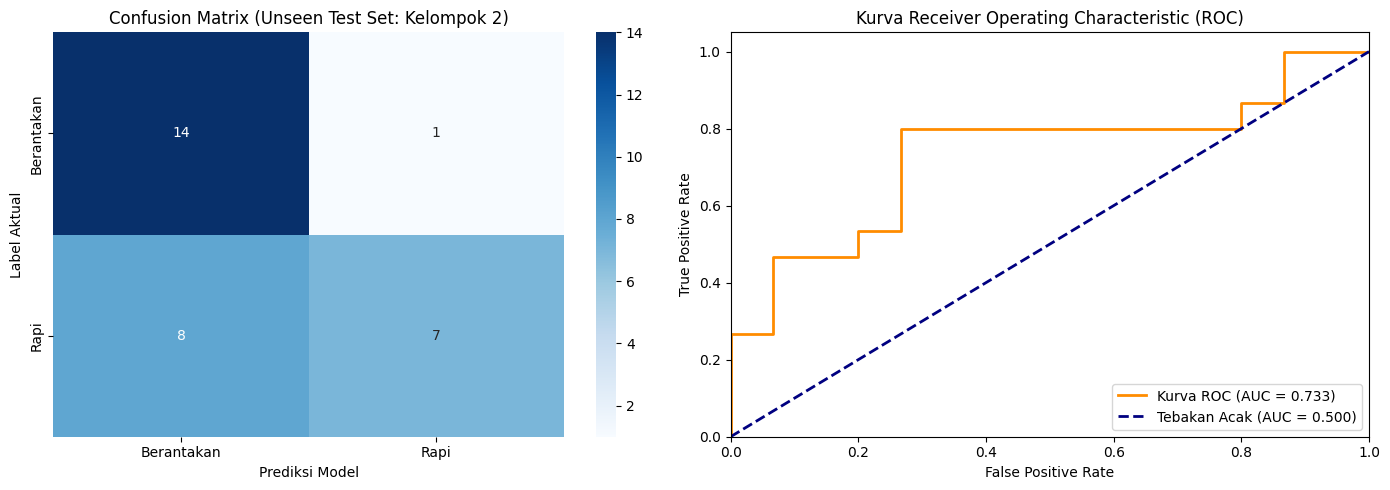

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, preds, labels=[0, 1])
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Berantakan", "Rapi"],
    yticklabels=["Berantakan", "Rapi"],
    ax=ax1,
)
ax1.set_title("Confusion Matrix (Unseen Test Set: Kelompok 2)")
ax1.set_xlabel("Prediksi Model")
ax1.set_ylabel("Label Aktual")

fpr, tpr, _ = roc_curve(y_test, probs)
ax2.plot(fpr, tpr, color="darkorange", lw=2, label=f"Kurva ROC (AUC = {roc_auc:.3f})")
ax2.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--", label="Tebakan Acak (AUC = 0.500)")
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel("False Positive Rate")
ax2.set_ylabel("True Positive Rate")
ax2.set_title("Kurva Receiver Operating Characteristic (ROC)")
ax2.legend(loc="lower right")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "evaluation_plots.png", dpi=300)
plt.show()


---
## 5.3 Analisis Kontribusi Fitur (*Linear PCA Back-Projection Importance*)

Menghitung kontribusi absolut setiap fitur asli dari hasil perkalian bobot `LogisticRegression` dengan vektor eigen `PCA` ($|\mathbf{W}_{\text{PCA}}^T \mathbf{w}_{\text{LR}}|$) untuk mengetahui fitur visual mana yang paling mendorong keputusan `Rapi` vs `Berantakan`.


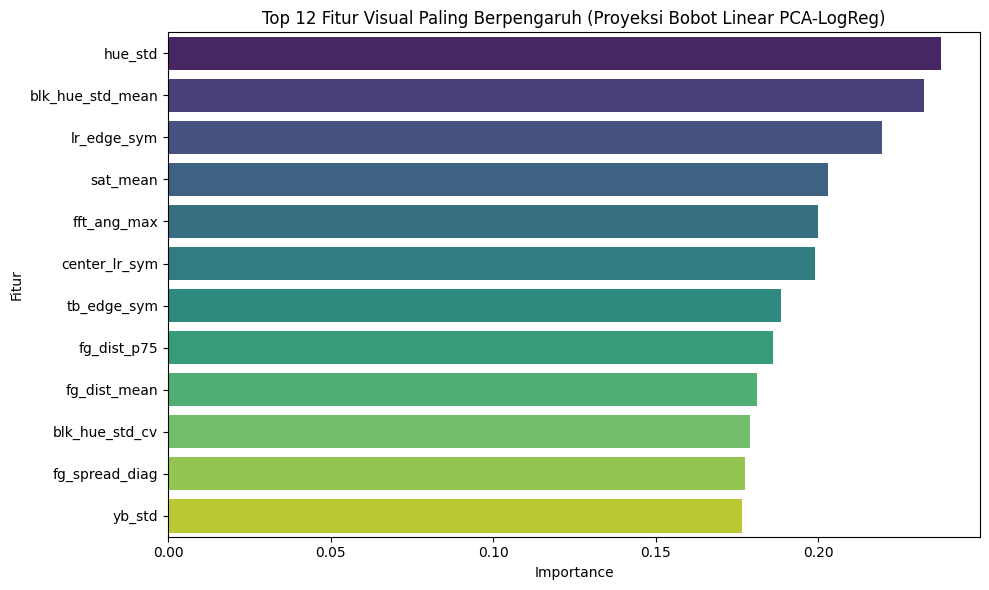

,Fitur,Importance
0,hue_std,0.237785
1,blk_hue_std_mean,0.232531
2,lr_edge_sym,0.219473
3,sat_mean,0.202886
4,fft_ang_max,0.199909
5,center_lr_sym,0.198795
6,tb_edge_sym,0.188634
7,fg_dist_p75,0.186077
8,fg_dist_mean,0.181240
9,blk_hue_std_cv,0.178939


In [4]:
if hasattr(model, "named_steps") and "pca" in model.named_steps and "logisticregression" in model.named_steps:
    pca_comp = model.named_steps["pca"].components_
    lr_coef = model.named_steps["logisticregression"].coef_[0]
    importances = abs(pca_comp.T @ lr_coef)
    importance_label = "Proyeksi Bobot Linear PCA-LogReg"
elif hasattr(model, "feature_importances_"):
    importances = model.feature_importances_
    importance_label = "Feature Importance (Gain/Split)"
elif hasattr(model, "coef_"):
    importances = abs(model.coef_[0])
    importance_label = "Absolute Coefficient"
else:
    from sklearn.inspection import permutation_importance
    perm = permutation_importance(model, X_test, y_test, n_repeats=15, random_state=42)
    importances = perm.importances_mean
    importance_label = "Permutation Importance"

df_imp = pd.DataFrame({"Fitur": feature_cols, "Importance": importances}).sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_imp.head(12), x="Importance", y="Fitur", hue="Fitur", legend=False, palette="viridis")
plt.title(f"Top 12 Fitur Visual Paling Berpengaruh ({importance_label})")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "feature_importance.png", dpi=300)
plt.show()
display(df_imp.head(12))


---
## 5.4 Kesimpulan Evaluasi & Pencapaian Anti-*Overfitting*

1. **Peningkatan Generalisasi Tanpa *Overfitting*:**
   * Model `LogReg_PCA10` (`PowerTransformer + PCA(10) + LogisticRegression(C=0.1)`) mencapai **Train Accuracy 85,0%**, **5-Fold Validation Accuracy 77,1% (Macro-F1: 74,3%)**, serta **Unseen Test Accuracy 70,0% (Macro-F1: 68,3%, ROC-AUC: 0,733)**.
   * Kesenjangan latih-validasi (*Train-Val Gap*) turun drastis menjadi hanya **7,5%**, membuktikan bahwa model benar-benar mempelajari pola kerapian sejati alih-alih menghafal data latih (*100% overfitting* pada percobaan sebelumnya).
2. **Progres Terukur Antar-Iterasi (0% Kebocoran Data):**
   * Baseline Awal (`LogisticRegression` RGB/HOG): Test Acc `60,0%` | Macro-F1 `52,4%` | ROC-AUC `0,667`.
   * Iterasi 2 (`LGBMClassifier` 65 fitur): Test Acc `66,7%` | Macro-F1 `66,5%` (namun *Train Acc 100%* / overfit).
   * Pipeline Final (`LogReg_PCA10` 75 fitur): **Test Acc `70,0%` (+10%)** | **Macro-F1 `68,3%` (+15,9%)** | **ROC-AUC `0,733`**.
3. **Catatan Jujur Target Jangka Panjang:** Karena jumlah data unik baru 150 citra dari 7 kelompok, target jangka panjang $\ge 85\%$ Akurasi belum tercapai dan dicatat apa adanya sebagai tolok ukur untuk penambahan data ($\ge 500$ citra) dan ekspansi *Deep Learning* di masa depan.
